# 第5回 結果の解釈 ― 貢献・ROAS・飽和曲線

**使い方**：上のセルから順に `Shift + Enter` で実行していきます。コードを書き換える必要はありません。
「🧪 実験」のセルだけは、値を変えて何度か実行してみてください。

**この回のゴール**

第4回で学習したモデルから、広告費を決める人が知りたい3つの答えを取り出します。

1. **売上の分解**：売上のうち、広告が生んだのはどれだけか
2. **チャネル別の貢献と費用対効果（ROAS）**：どのチャネルが効いているか
3. **飽和曲線と限界ROAS**：どのチャネルに、まだ伸びしろがあるか

そして、すべての答えに**「どのくらい確かか」（信用区間）**を付けます。これがベイズ推定でMMMを作る一番の利点です。

**所要時間**：60分ほど。重い計算はありません（学習済みの結果を読み込むだけです）。

**前提**：第4回で保存した学習結果（`mmm_cs1.nc`）を使います。まだ無いときは、この回の中で学習します（3〜13分）。

> **この教材について**
>
> - PyMC-Marketing の公式ケーススタディ「[MMM End-to-End Case Study](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_case_study.html)」を、日本語で順に学べるように組み立て直した教材です（作成：Birdwing Technologies合同会社）。
> - コードは本家（Apache License 2.0）をもとに改変しています。解説・図・小課題は独自に加えたものです。
> - データは本家と同じ、公開されている学習用のデータです。
> - 解説ページと全体の目次：<https://bwtech.co.jp/learn/mmm/05-results>

## 0. 準備

最初のセルは、どの回にも共通の準備です。**Google Colab でも、自分のPCでも、そのまま実行できます。**

- データがなければダウンロードします（約80KB）
- グラフに日本語を表示できるようにします
- Google Colab のときだけ、必要なライブラリを入れます（数分かかります）
- 学習結果の置き場所を決めます（Colab のときは Google ドライブ。初回に許可の画面が出ます）

In [1]:
# ===== 共通の準備（Google Colab でも、自分のPCでも、このまま実行できます） =====
import subprocess, sys, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# --- g++（計算を速くする部品）がない環境では、その旨を PyTensor に伝える（WARNING が短くなる） ---
import os, shutil
if shutil.which("g++") is None:
    os.environ["PYTENSOR_FLAGS"] = "cxx="

# --- Colab のときだけ、ライブラリを入れる（数分かかります） ---
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymc-marketing==0.19.2", "nutpie==0.16.8"], check=True)

# --- ファイルの置き場所 ---
BASE_DIR = Path("/content/mmm-pymc") if IN_COLAB else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "case_study_data.csv"

# --- 学習結果の置き場所 ---
# Colab は接続が切れるとファイルが消えるので、学習結果は Google ドライブに置く（初回に許可の画面が出ます）。
# ドライブを使いたくないときは USE_DRIVE = False にする（その場合は、回ごとに学習し直します）。
USE_DRIVE = True
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    MODEL_DIR = Path("/content/drive/MyDrive/mmm-pymc/models")
else:
    MODEL_DIR = BASE_DIR / "models"
MODEL_PATH = MODEL_DIR / "mmm_cs1.nc"

# --- データの取得（なければダウンロードする） ---
DATA_URL = "https://raw.githubusercontent.com/pymc-labs/pymc-marketing/0.19.2/data/case_study_data.csv"
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

# --- グラフの日本語フォント ---
import matplotlib.pyplot as plt
from matplotlib import font_manager

def setup_japanese_font():
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["Meiryo", "Yu Gothic", "Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "IPAGothic"]:
        if name in installed:
            plt.rcParams["font.family"] = name
            return name
    # 日本語フォントが見つからないとき（Colab など）は、フォント入りのパッケージを入れる
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib-fontja"], check=True)
    import matplotlib_fontja  # 読み込むだけで日本語フォント（IPAexGothic）が設定される
    return "IPAexGothic"

font_name = setup_japanese_font()
plt.rcParams["axes.unicode_minus"] = False    # マイナス記号の文字化けを防ぐ

print("実行環境:", "Google Colab" if IN_COLAB else "自分のPC")
print("データ:", DATA_PATH.relative_to(BASE_DIR).as_posix(), "（取得済み）")
print("日本語フォント:", font_name)

実行環境: 自分のPC
データ: data/case_study_data.csv （取得済み）
日本語フォント: Meiryo


この回で使うライブラリを読み込みます。

In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pymc_marketing.mmm.multidimensional import MMM


WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


### 学習結果を読み込む

第4回で保存した学習結果（`mmm_cs1.nc`）を読み込みます。

- 見つかったとき → 読み込むだけ（数秒）
- 見つからないとき → 第4回と同じ設定で、この場で学習して保存します（**3〜13分**）

In [3]:
def load_or_fit_model():
    """学習結果を読み込む。なければ、第4回と同じ設定で学習して保存する。"""
    if MODEL_PATH.exists():
        print("保存済みの学習結果を読み込みました:", MODEL_PATH.name)
        return MMM.load(str(MODEL_PATH))

    print("学習結果が見つからないので、第4回と同じ設定で学習します（3〜13分）。")
    from pymc_extras.prior import Prior
    from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation

    raw = pd.read_csv(DATA_PATH, parse_dates=["wk_strt_dt"])
    names = {
        "mdsp_dm": "DM", "mdsp_inst": "折込", "mdsp_nsp": "新聞", "mdsp_audtr": "ラジオ",
        "mdsp_vidtr": "TV", "mdsp_so": "ソーシャル", "mdsp_on": "ディスプレイ",
    }
    channels = list(names.values())
    controls = [c for c in raw.columns if c.startswith("hldy_")]
    data = raw[["wk_strt_dt", "sales", *names.keys(), *controls]].rename(columns=names)
    train = data[data["wk_strt_dt"] <= pd.to_datetime("2018-02-01")]
    X_tr, y_tr = train.drop(columns="sales"), train["sales"]
    share = X_tr[channels].sum() / X_tr[channels].sum().sum()

    model = MMM(
        model_config={
            "intercept": Prior("Normal", mu=0.2, sigma=0.05),
            "saturation_beta": Prior("HalfNormal", sigma=share[channels].to_numpy(), dims="channel"),
            "gamma_control": Prior("Normal", mu=0, sigma=1, dims="control"),
            "gamma_fourier": Prior("Laplace", mu=0, b=1, dims="fourier_mode"),
            "likelihood": Prior("TruncatedNormal", lower=0, sigma=Prior("HalfNormal", sigma=1)),
        },
        date_column="wk_strt_dt", target_column="sales",
        channel_columns=channels, control_columns=controls,
        adstock=GeometricAdstock(l_max=6), saturation=LogisticSaturation(), yearly_seasonality=5,
    )
    model.build_model(X_tr, y_tr)
    model.add_original_scale_contribution_variable(
        var=["channel_contribution", "control_contribution", "intercept_contribution",
             "yearly_seasonality_contribution", "y"]
    )
    model.fit(X_tr, y_tr, chains=4, tune=1_000, draws=1_000, target_accept=0.9,
              nuts_sampler="nutpie", random_seed=42)
    model.sample_posterior_predictive(X_tr, extend_idata=True, combined=True, random_seed=42,
                                      compile_kwargs={"mode": "NUMBA"})
    for group in ["warmup_posterior", "warmup_sample_stats"]:
        if group in model.idata.groups():
            del model.idata[group]
    MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
    model.save(str(MODEL_PATH))
    return model

mmm = load_or_fit_model()
posterior = mmm.idata["posterior"]
print("サンプル数:", posterior.sizes["chain"] * posterior.sizes["draw"])


保存済みの学習結果を読み込みました: mmm_cs1.nc


サンプル数: 4000


### この回で使う材料

学習結果の中には、4,000組のパラメータそれぞれについて計算した「貢献」が入っています。まず材料に名前をつけます。

| 変数 | 中身 | 形 |
|---|---|---|
| `channel_contrib` | 週ごと・チャネルごとの、広告による売上 | 4,000組 × 183週 × 7チャネル |
| `base_contrib` | ベース売上（週あたり） | 4,000組 |
| `control_contrib` | 祝日による売上 | 4,000組 × 183週 × 22祝日 |
| `season_contrib` | 季節による売上 | 4,000組 × 183週 |
| `spend` | 実際の広告費 | 183週 × 7チャネル |
| `sales` | 実際の売上 | 183週 |

**4,000組すべてについて同じ計算をする**のがポイントです。そうすると、答えも4,000個得られ、その広がりが「答えの確かさ」になります。

In [4]:
S = ("chain", "draw")      # サンプルの次元。この2つについて集計すると、4,000組の要約になる

channel_contrib = posterior["channel_contribution_original_scale"]
base_contrib = posterior["intercept_contribution_original_scale"]
control_contrib = posterior["control_contribution_original_scale"]
season_contrib = posterior["yearly_seasonality_contribution_original_scale"]

const = mmm.idata["constant_data"]
spend = const["channel_data"]            # 週 × チャネル
sales = const["target_data"]             # 週
dates = pd.to_datetime(sales["date"].values)
channels = list(spend["channel"].values)
n_weeks = len(dates)

def summarize(x, digits=2):
    # 4,000個の答えを「中央値と94%の範囲」にまとめる
    q = x.quantile([0.03, 0.5, 0.97], dim=S)
    out = q.to_pandas()
    if isinstance(out, pd.DataFrame):
        out = out.T
        out.columns = ["下端（3%）", "中央値", "上端（97%）"]
    else:
        out.index = ["下端（3%）", "中央値", "上端（97%）"]
    return out.round(digits)

print("期間:", dates.min().date(), "〜", dates.max().date(), f"（{n_weeks}週）")
print("売上の合計:", round(float(sales.sum()) / 1e8, 1), "億")
print("広告費の合計（7チャネル）:", round(float(spend.sum()) / 1e8, 2), "億")

期間: 2014-08-03 〜 2018-01-28 （183週）
売上の合計: 201.1 億
広告費の合計（7チャネル）: 3.25 億


> **単位についての注意**：このデータには通貨や単位の説明がありません。売上の合計は約201億、広告費の合計は約3.3億で、広告費は売上の約1.6%です。
> 売上と広告費が同じ単位かどうかは確認できないので、ROAS は**絶対値よりも、チャネル間の比較と確かさの幅**に注目します。

## 1. 売上の分解

### 1-1. 売上は何でできているか

MMMは売上を「ベース ＋ 広告 ＋ 祝日 ＋ 季節」の足し算で説明します。183週の合計で、それぞれが売上の何%を占めるかを出します。

In [5]:
total_sales = float(sales.sum())

parts = {
    "ベース": base_contrib * n_weeks,
    "広告（7チャネル合計）": channel_contrib.sum(dim=("date", "channel")),
    "祝日": control_contrib.sum(dim=("date", "control")),
    "季節": season_contrib.sum(dim="date"),
}
decomp = pd.DataFrame({name: summarize(v / total_sales * 100, 1) for name, v in parts.items()}).T
decomp.columns = [c + " %" for c in decomp.columns]
decomp

,下端（3%） %,中央値 %,上端（97%） %
ベース,40.9,61.3,77.3
広告（7チャネル合計）,21.5,36.8,56.6
祝日,-4.4,-0.5,3.5
季節,0.2,1.2,2.1


**読み方**（実際の売上合計に対する割合）

- **ベース**：約61%。広告も祝日もなくても得られる売上です。ブランド力、店舗、リピート客などに当たります
- **広告**：約37%。ただし94%の範囲は約22%〜57%と広い
- **祝日・季節**：合計するとほぼ0%。年末に押し上げ、ほかの時期に押し下げるので、年間で均すと打ち消し合います

**大事な点**：「広告の貢献は37%です」と言い切れるほど、確かではありません。
ベースが多くて広告が少ないのか、その逆なのか、このデータだけでははっきり分けられていません（ベースの範囲も約41%〜77%です）。

### 1-2. 時系列で見る

週ごとに「広告がなくても得られた売上」と「広告の上乗せ」を積み上げて、実際の売上と重ねます（4,000組の平均）。

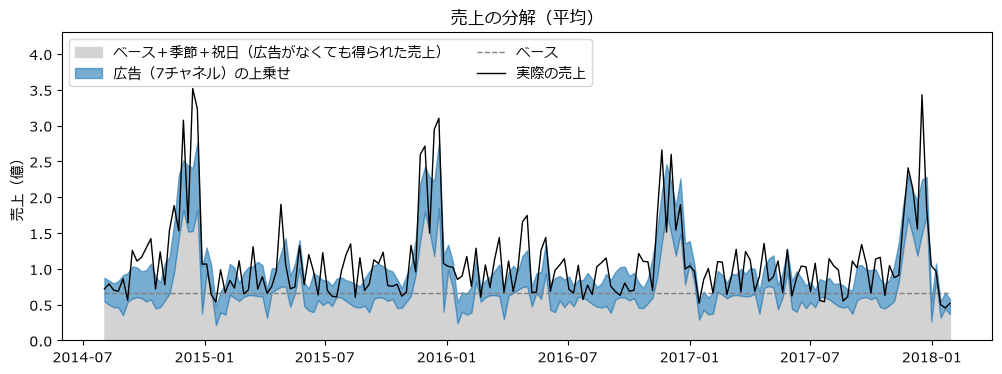

In [6]:
base_line = np.full(n_weeks, float(base_contrib.mean()))
season_holiday = (season_contrib.mean(dim=S) + control_contrib.sum(dim="control").mean(dim=S)).to_numpy()
media_line = channel_contrib.sum(dim="channel").mean(dim=S).to_numpy()

level1 = base_line / 1e8
level2 = (base_line + season_holiday) / 1e8
level3 = (base_line + season_holiday + media_line) / 1e8

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(dates, 0, level2, color="lightgray", label="ベース＋季節＋祝日（広告がなくても得られた売上）")
ax.fill_between(dates, level2, level3, color="C0", alpha=0.6, label="広告（7チャネル）の上乗せ")
ax.plot(dates, level1, color="gray", linestyle="--", linewidth=1, label="ベース")
ax.plot(dates, sales.to_numpy() / 1e8, color="black", linewidth=1, label="実際の売上")
ax.set_ylabel("売上（億）")
ax.set_title("売上の分解（平均）")
ax.set_ylim(0, 4.3)
ax.legend(loc="upper left", ncol=2);

**読み方**

- **灰色**：広告がなくても得られた売上。点線のベース（毎週一定）に、季節と祝日の影響を足し引きしたものです。年末に大きく盛り上がり、ふだんの週はベースより少し下がります
- **青**：その上に広告が積んだ売上。年末は広告費が増えるので、青も厚くなります
- **年末の山**：大部分は灰色（季節と祝日）が説明しています。第1回で「年末の売上増を広告のおかげと言い切れるか」と問いかけましたが、モデルは「多くは季節によるもの」と答えています
- **黒い線が青の上に飛び出す週**：モデルが説明できていない売上です。第4回で見たとおり、このモデルの当てはまりは R² 0.69 で、ふだんの週の上下はとらえきれていません

## 2. チャネル別の貢献

### 2-1. 貢献額（183週の合計）

広告全体の貢献を、チャネルごとに分けます。

,下端（3%）,中央値,上端（97%）,広告費（億）
channel,,,,
ディスプレイ,1.39,17.70,51.34,0.39
TV,0.99,13.54,33.65,0.33
DM,0.46,9.65,40.21,1.46
折込,0.46,7.06,23.26,0.16
新聞,0.43,6.90,19.28,0.53
ラジオ,0.28,5.66,22.73,0.22
ソーシャル,0.18,3.78,13.86,0.17


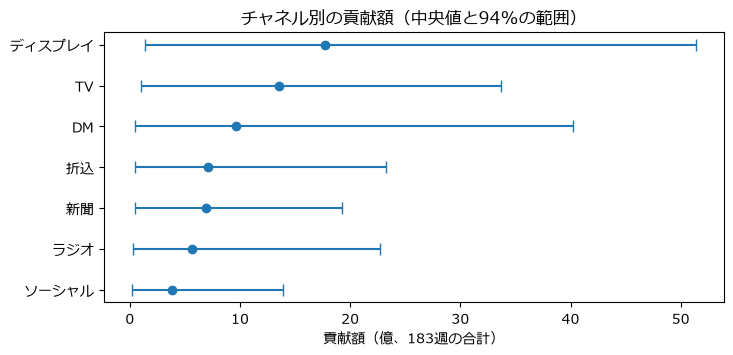

In [7]:
contrib_total = channel_contrib.sum(dim="date") / 1e8        # 4,000組 × 7チャネル（億）
contrib_table = summarize(contrib_total)
contrib_table["広告費（億）"] = (spend.sum(dim="date") / 1e8).to_pandas().round(2)
contrib_table = contrib_table.sort_values("中央値", ascending=False)

def interval_plot(ax, table, xlabel, color="C0"):
    # 表（下端・中央値・上端）を、丸と横棒で描く
    t = table.iloc[::-1]
    ax.errorbar(t["中央値"], t.index,
                xerr=[t["中央値"] - t["下端（3%）"], t["上端（97%）"] - t["中央値"]],
                fmt="o", capsize=4, color=color)
    ax.set_xlabel(xlabel)

fig, ax = plt.subplots(figsize=(8, 3.5))
interval_plot(ax, contrib_table, "貢献額（億、183週の合計）")
ax.set_title("チャネル別の貢献額（中央値と94%の範囲）")
contrib_table

**読み方**

- 中央値では、ディスプレイ（約17.7億）、TV（約13.5億）、DM（約9.7億）の順です
- しかし**区間がとても広い**。DM は約0.5億〜40億で、下端と上端で80倍以上の差があります
- 7チャネルすべての区間が重なっています。**「どのチャネルの貢献が一番大きいか」は、このデータからは決められません**
- DM は広告費が最大（1.46億）なのに、貢献の中央値は3位です

中央値だけを並べた表を作ると、あたかも順位がはっきりしているように見えてしまいます。必ず区間と一緒に見ます。

### 2-2. 貢献シェアと費用シェア

第3回で、学習前（事前）の貢献シェアを見ました。DM は平均48%で、費用シェアとほぼ同じでした。学習後にどう変わったかを見ます。

,下端（3%）,中央値,上端（97%）,費用シェア
channel,,,,
DM,0.7,13.4,45.2,45.0
新聞,0.6,9.4,27.0,16.3
ディスプレイ,2.2,24.4,55.6,11.9
TV,1.5,18.4,46.4,10.0
ラジオ,0.4,7.8,30.2,6.8
ソーシャル,0.3,5.2,18.4,5.2
折込,0.6,9.5,32.7,4.8


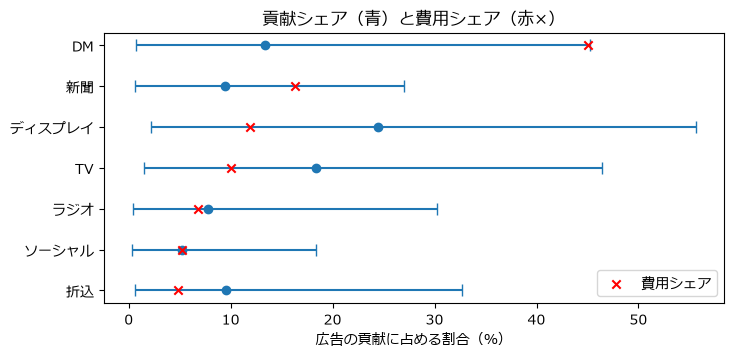

In [8]:
contrib_share = contrib_total / contrib_total.sum(dim="channel") * 100     # 4,000組 × 7チャネル（%）
share_table = summarize(contrib_share, 1)
spend_share = (spend.sum(dim="date") / spend.sum() * 100).to_pandas()
share_table["費用シェア"] = spend_share.round(1)
share_table = share_table.sort_values("費用シェア", ascending=False)

fig, ax = plt.subplots(figsize=(8, 3.5))
interval_plot(ax, share_table, "広告の貢献に占める割合（%）")
ax.scatter(share_table["費用シェア"].iloc[::-1], share_table.index[::-1], marker="x", color="red", zorder=3, label="費用シェア")
ax.set_title("貢献シェア（青）と費用シェア（赤×）")
ax.legend(loc="lower right")
share_table

**読み方**

- **DM**：費用シェア45%に対して、貢献シェアの中央値は約13%。第3回の事前（平均48%）から大きく下がりました。データが動かした部分です
- **ディスプレイ**（費用12% → 貢献24%）、**TV**（10% → 18%）、**折込**（5% → 10%）は、費用シェアより貢献シェアが大きい
- 新聞（16% → 9%）は逆に小さい
- ただし、どのチャネルも赤い×は青い横棒の範囲内にあります（DM は上端すれすれ）。「費用シェアどおりの貢献」という可能性も、完全には否定できていません

「費用に対して貢献が大きいか小さいか」は、次の ROAS でそのまま数字になります。

## 3. ROAS（費用対効果）

### 3-1. 定義

**ROAS**（Return On Ad Spend）は、広告費1に対して、売上がいくら生まれたかです。

$$
\text{ROAS}_c \;=\; \frac{\text{チャネル } c \text{ の貢献額の合計}}{\text{チャネル } c \text{ の広告費の合計}}
$$

ROAS が 5 なら「広告費1に対して売上5」。1を下回ると、使った広告費より生まれた売上のほうが小さいことになります（利益で見るなら、粗利率も考える必要があります）。

貢献額が4,000個あるので、ROAS も4,000個計算できます。

,下端（3%）,中央値,上端（97%）,平均,ROASが1を超える確率
channel,,,,,
ディスプレイ,3.6,45.8,132.9,52.3,0.99
折込,3.0,45.4,149.6,54.2,0.99
TV,3.0,41.6,103.4,44.7,0.99
ラジオ,1.3,25.5,102.2,32.7,0.98
ソーシャル,1.1,22.2,81.4,27.9,0.97
新聞,0.8,13.0,36.4,14.6,0.96
DM,0.3,6.6,27.5,8.6,0.92


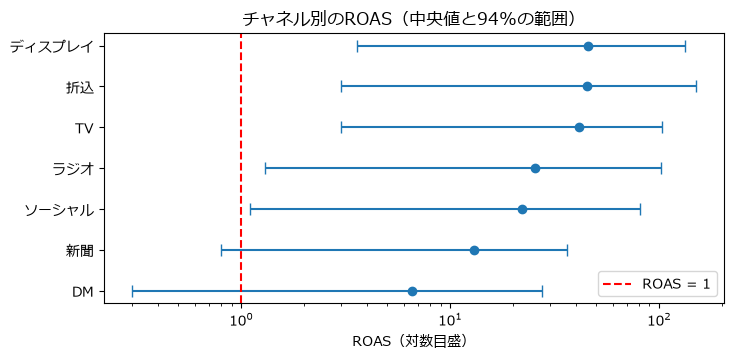

In [9]:
roas = channel_contrib.sum(dim="date") / spend.sum(dim="date")      # 4,000組 × 7チャネル
roas_table = summarize(roas, 1)
roas_table["平均"] = roas.mean(dim=S).to_pandas().round(1)
roas_table["ROASが1を超える確率"] = (roas > 1).mean(dim=S).to_pandas().round(2)
roas_table = roas_table.sort_values("中央値", ascending=False)

fig, ax = plt.subplots(figsize=(8, 3.5))
interval_plot(ax, roas_table, "ROAS（対数目盛）")
ax.set_xscale("log")
ax.axvline(1, color="red", linestyle="--", label="ROAS = 1")
ax.set_title("チャネル別のROAS（中央値と94%の範囲）")
ax.legend(loc="lower right")
roas_table

**読み方**

- 中央値は、ディスプレイ・折込・TV が約42〜46、ラジオ・ソーシャルが約22〜25、新聞が約13、DM が約6.6
- 区間は非常に広い（折込は約3〜150）。横軸は対数目盛（1目盛りで10倍）であることに注意してください
- 「ROAS が1を超える確率」は、DM で92%、ほかは96%以上です

> **本家との比較**：本家ノートブックの ROAS の図は、点が**平均**です。図から読み取った値は、DM 約8.5、新聞 約14.5、ソーシャル 約29、ラジオ 約34、TV 約46、折込とディスプレイ 約53。
> 上の表の「平均」の列とほぼ一致します（学習の設定と乱数が違うので、完全には一致しません）。
> この教材では、極端に大きい値に引っぱられにくい**中央値**を主に使います。分布が右に長く伸びているので、平均は中央値より大きくなります。
> また、本家の区間は HDI（もっとも密度の高い94%の範囲）、この教材は両端3%ずつを除いた範囲なので、端の値は少し違います。

**この数字をそのまま信じてよいか？**　ROAS が40を超えるというのは、実務の感覚ではかなり高い値です。理由を考えます。

- 広告費は売上の約1.6%しかありません。一方、モデルは売上の約37%を広告に割り当てました。だから平均の ROAS は 37 ÷ 1.6 ≒ 23 になります。計算としては合っています
- 疑うべき点①：売上と広告費の単位が同じかどうか、データの説明がなく分かりません
- 疑うべき点②：ベースと広告の切り分けが不確かです（1章。広告は22%〜57%の幅）
- 疑うべき点③：このモデルは値引きなどの変数を使っていません。年末の値引きによる売上を、同じ時期に増える広告の効果として数えているおそれがあります（私の解釈で、確かめてはいません）

**実務では、MMMが出した数字が現場の感覚と大きくずれていたら、まずモデルとデータを疑います。**
このデータで信頼しやすいのは、絶対値よりも「チャネル同士の比較」です。次で確かめます。

### 3-2. チャネル同士を比べる

区間が重なっていると、「どちらが上か」は表からは判断できません。
そこで、4,000組のうち「チャネルAのROASがチャネルBより高かった」組の割合を数えます。これが「AがBより効率が良い確率」です。

表は「**行**のチャネルが、**列**のチャネルよりROASが高い確率」です。

In [10]:
order = list(roas_table.index)
prob = pd.DataFrame(index=order, columns=order, dtype=float)
for a in order:
    for b in order:
        if a != b:
            prob.loc[a, b] = float((roas.sel(channel=a) > roas.sel(channel=b)).mean())
prob.round(2).fillna("")

,ディスプレイ,折込,TV,ラジオ,ソーシャル,新聞,DM
ディスプレイ,,0.5,0.53,0.65,0.7,0.87,0.91
折込,0.5,,0.54,0.66,0.7,0.82,0.9
TV,0.47,0.46,,0.65,0.69,0.82,0.91
ラジオ,0.35,0.34,0.35,,0.54,0.69,0.81
ソーシャル,0.3,0.3,0.31,0.46,,0.7,0.8
新聞,0.13,0.18,0.18,0.31,0.3,,0.69
DM,0.09,0.1,0.09,0.19,0.2,0.31,


**読み方**

- **上位3つ（ディスプレイ・折込・TV）は、互いに0.46〜0.54**。ほぼ五分五分で、順位は分かりません
- **DM の列**を見ると、ほかの全チャネルが DM より高い確率は0.69〜0.91。上位3つに対しては約0.9です

言えること・言えないことを分けます。

- ✅ 言える：「DM は、ディスプレイ・折込・TV より効率が低い可能性が高い（約9割）」
- ❌ 言えない：「ROAS が一番高いのはディスプレイです」

区間が広くても、**比較の確率**にすると、はっきり言えることが見つかる場合があります。これはベイズ推定の強みです。

## 4. 飽和曲線

### 4-1. モデルの中身を自分の手で再現する

ROAS は「これまでの平均」です。「これから増やしたらどうなるか」を知るには、飽和曲線が必要です。

その前に、第2回で作った `adstock` と `saturation` の関数で、モデルが計算した貢献を再現できるか確かめます。
モデルの中では、次の順に計算されています（スケーリングは第3回で確認しました）。

$$
\text{貢献}_{c,t} \;=\; \beta_c \cdot S\!\left(\lambda_c \cdot A\!\left(\frac{x_{c,t}}{\text{最大費用}_c};\ \alpha_c\right)\right) \times \text{最大売上}
$$

第2回との違いは1つだけです。PyMC-Marketing の adstock は、重みの合計が1になるように割っています（**正規化**）。
こうすると、毎週同じ額を出し続けたとき、adstock後の値が元の広告費と同じになります。

In [11]:
def adstock(x, alpha, l_max=6):
    w = alpha ** np.arange(l_max)
    w = w / w.sum()                        # 正規化：重みの合計を1にする
    return np.convolve(x, w)[:len(x)]

def saturation(x, lam):
    return (1 - np.exp(-lam * x)) / (1 + np.exp(-lam * x))

channel_scale = const["channel_scale"]                    # チャネルごとの最大費用
target_scale = float(const["target_scale"].values[0])     # 最大売上

# 4,000組のうち最初の1組のパラメータで、TV の貢献を手計算する
ch = "TV"
one = posterior.isel(chain=0, draw=0).sel(channel=ch)
alpha, lam, beta = float(one["adstock_alpha"]), float(one["saturation_lam"]), float(one["saturation_beta"])

x_scaled = (spend.sel(channel=ch) / channel_scale.sel(channel=ch)).to_numpy()
by_hand = beta * saturation(adstock(x_scaled, alpha), lam) * target_scale
by_model = channel_contrib.isel(chain=0, draw=0).sel(channel=ch).to_numpy()

print(f"α = {alpha:.3f}, λ = {lam:.3f}, β = {beta:.3f}")
print("手計算（最初の3週）:", by_hand[:3].round(0))
print("モデル（最初の3週）:", by_model[:3].round(0))
print("最大のずれ:", float(np.abs(by_hand - by_model).max()))

α = 0.281, λ = 2.369, β = 0.068
手計算（最初の3週）: [3985017. 3133014. 2252211.]
モデル（最初の3週）: [3985017. 3133014. 2252211.]
最大のずれ: 3.725290298461914e-09


手計算とモデルの値が一致しました。モデルの中身は、第2回で作った2つの関数と係数 β だけです。

### 4-2. 飽和曲線を描く

「毎週 $x$ の広告費を出し続けたら、週あたりの貢献はいくらになるか」を、チャネルごとに描きます。
出し続ける場合は adstock後の値が $x$ と同じになるので、式は次のとおりです。

$$
\text{週あたりの貢献}(x) \;=\; \beta_c \cdot S\!\left(\lambda_c \cdot \frac{x}{\text{最大費用}_c}\right) \times \text{最大売上}
$$

4,000組それぞれで曲線を描き、中央値と94%の範囲を帯で示します。縦の点線は、実際の週平均の広告費です。

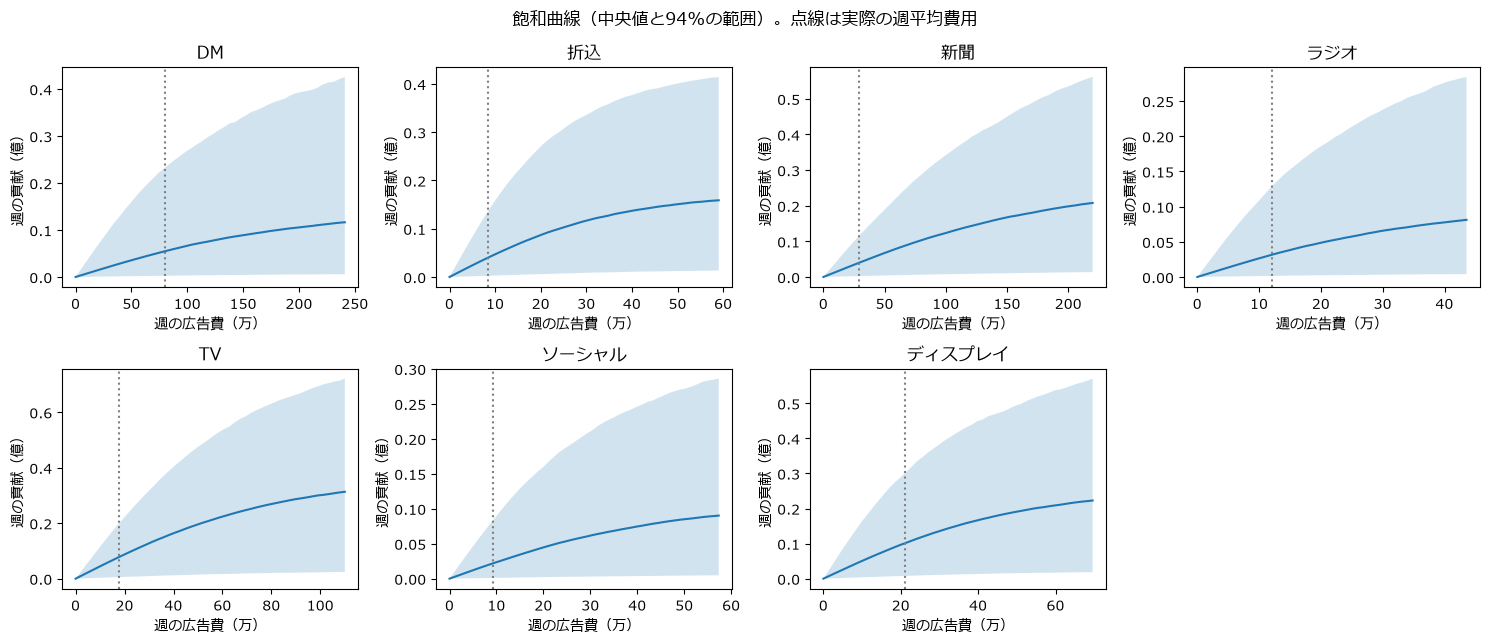

In [12]:
beta_s = posterior["saturation_beta"]
lam_s = posterior["saturation_lam"]
mean_spend = spend.mean(dim="date")

def weekly_contribution(channel, x):
    # 毎週 x の広告費を出し続けたときの、週あたりの貢献（4,000組ぶん）
    b = beta_s.sel(channel=channel)
    u = lam_s.sel(channel=channel) * x / float(channel_scale.sel(channel=channel))
    return b * (1 - np.exp(-u)) / (1 + np.exp(-u)) * target_scale

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, c in zip(axes.ravel(), channels):
    x_max = float(channel_scale.sel(channel=c))
    grid = np.linspace(0, x_max, 50)
    curves = np.stack([weekly_contribution(c, x).to_numpy().ravel() for x in grid])     # 50点 × 4,000組
    low, med, high = np.quantile(curves, [0.03, 0.5, 0.97], axis=1) / 1e8
    ax.fill_between(grid / 1e4, low, high, alpha=0.2)
    ax.plot(grid / 1e4, med)
    ax.axvline(float(mean_spend.sel(channel=c)) / 1e4, color="gray", linestyle=":")
    ax.set_title(c)
    ax.set_xlabel("週の広告費（万）")
    ax.set_ylabel("週の貢献（億）")
axes.ravel()[-1].axis("off")
plt.suptitle("飽和曲線（中央値と94%の範囲）。点線は実際の週平均費用")
plt.tight_layout()

**読み方**

- **線（中央値）**：どのチャネルも、点線（実際の週平均）のあたりではまだ直線に近く、頭打ちの手前にいます。右へ行くほど、ゆるやかに曲がります
- **帯（94%の範囲）**：非常に広く、下端はほぼ0に張りついています。「ほとんど効いていない」から「かなり効いている」まで、どれもありうるということです
- **グラフの右端**は、過去に実際に出した最大の週の費用です。それより右は、データのない領域の推測（外挿）になるので描いていません

曲線の曲がり方を決める λ の事後分布は、第4回の表で見ると平均2.5〜3.3で、事前分布（平均3）とほとんど変わっていません。
つまり**「どこで頭打ちになるか」は、データよりも事前の仮定で決まっています**。α と同じ状況です。

## 5. 限界ROAS ― 次の1円はどこに使うべきか

第2回で学んだとおり、予算配分で比べるのは「平均の費用対効果」ではなく「**限界効果**」です。

- **平均のROAS**：これまで使った広告費全体の効率（曲線の原点と現在地を結んだ線の傾き）
- **限界ROAS**：いまの水準から広告費を少し増やしたとき、追加の1に対して増える売上（現在地での曲線の傾き）

式は、飽和曲線を広告費 $x$ で微分したものです。

$$
\text{限界ROAS}(x) \;=\; \beta_c \cdot \frac{\lambda_c}{\text{最大費用}_c} \cdot \frac{2\,e^{-u}}{(1+e^{-u})^2} \times \text{最大売上},
\qquad u = \lambda_c \cdot \frac{x}{\text{最大費用}_c}
$$

実際の週平均の広告費を現在地として、チャネルごとに計算します。

In [13]:
u = lam_s * mean_spend / channel_scale
avg_roas_now = beta_s * (1 - np.exp(-u)) / (1 + np.exp(-u)) * target_scale / mean_spend
marginal_roas = beta_s * lam_s / channel_scale * 2 * np.exp(-u) / (1 + np.exp(-u)) ** 2 * target_scale
sat_level = (1 - np.exp(-u)) / (1 + np.exp(-u))

m_table = summarize(marginal_roas, 1)
m_table.columns = ["限界ROAS 下端", "限界ROAS 中央値", "限界ROAS 上端"]
m_table.insert(0, "週平均費用（万）", (mean_spend / 1e4).to_pandas().round(1))
m_table.insert(1, "平均ROAS 中央値", avg_roas_now.quantile(0.5, dim=S).to_pandas().round(1))
m_table["限界÷平均"] = (marginal_roas / avg_roas_now).quantile(0.5, dim=S).to_pandas().round(2)
m_table["頭打ちの度合い"] = sat_level.quantile(0.5, dim=S).to_pandas().round(2)
m_table.sort_values("限界ROAS 中央値", ascending=False)

,週平均費用（万）,平均ROAS 中央値,限界ROAS 下端,限界ROAS 中央値,限界ROAS 上端,限界÷平均,頭打ちの度合い
channel,,,,,,,
折込,8.5,47.5,3.0,45.3,145.5,0.97,0.22
TV,17.8,43.9,3.0,42.3,105.0,0.97,0.20
ディスプレイ,21.1,47.9,3.4,41.4,108.5,0.91,0.37
ラジオ,12.2,26.1,1.1,23.3,88.1,0.94,0.30
ソーシャル,9.3,23.7,1.1,22.7,83.3,0.97,0.19
新聞,28.9,13.7,0.8,13.5,37.8,0.99,0.14
DM,79.9,6.8,0.3,5.7,21.4,0.90,0.38


**読み方**

- **頭打ちの度合い**（0〜1。1に近いほど頭打ち）は0.14〜0.38。週平均の水準では、どのチャネルもまだ曲線の急な部分にいます
- そのため**限界ROASは平均ROASとほぼ同じ**（限界÷平均が0.90〜0.99）。比較的頭打ちに近いのは DM とディスプレイです
- 限界ROASの中央値は、折込・TV・ディスプレイ（41〜45）＞ラジオ・ソーシャル（約23）＞新聞（約14）＞DM（約6）

**予算配分への示唆**：限界ROASの低い DM から、高い折込・TV・ディスプレイへ予算を移すと、同じ総額で売上が増える**可能性が高い**。これが第7回の出発点です。

**ただし、3つの注意があります。**

1. 限界ROASの区間も広い（TVで約3〜105）。「増える可能性が高い」のであって、「必ず増える」ではありません
2. これは週平均の水準での話です。TVは年末にふだんの約3.5倍を出しています（第1回）。年末は曲線のもっと右にいて、頭打ちに近づいています
3. 曲線の曲がり方（λ）は、ほぼ事前の仮定です。大きく増額した先の予測ほど、仮定に頼っています

## 6. 🧪 実験：あるチャネルの広告費を変えたら

`CHANNEL` と `CHANGE` を変えて実行してください。「毎週の広告費を、いまの週平均の何倍にするか」を指定します。

- `CHANGE = 1.2`：20%増やす
- `CHANGE = 0.5`：半分にする
- `CHANGE = 2.0`：2倍にする

TV：週の広告費 17.8万 → 21.3万（年間の費用の変化 +0.02億）
年間の売上の変化：中央値 +0.77億（94%の範囲 +0.06億 〜 +1.91億）
変化分のROAS：中央値 41.7（94%の範囲 3.0 〜 103.4）


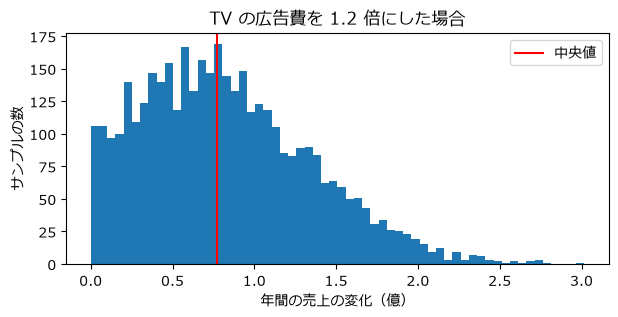

In [14]:
CHANNEL = "TV"
CHANGE = 1.2

x_now = float(mean_spend.sel(channel=CHANNEL))
x_new = x_now * CHANGE
delta = weekly_contribution(CHANNEL, x_new) - weekly_contribution(CHANNEL, x_now)     # 週あたりの売上の変化（4,000組）
delta_year = delta * 52 / 1e8
cost_year = (x_new - x_now) * 52 / 1e8

q = delta_year.quantile([0.03, 0.5, 0.97]).to_numpy()
print(f"{CHANNEL}：週の広告費 {x_now / 1e4:.1f}万 → {x_new / 1e4:.1f}万（年間の費用の変化 {cost_year:+.2f}億）")
print(f"年間の売上の変化：中央値 {q[1]:+.2f}億（94%の範囲 {q[0]:+.2f}億 〜 {q[2]:+.2f}億）")
if CHANGE != 1:
    inc = (delta_year / cost_year).quantile([0.03, 0.5, 0.97]).to_numpy()
    print(f"変化分のROAS：中央値 {inc[1]:.1f}（94%の範囲 {inc[0]:.1f} 〜 {inc[2]:.1f}）")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(delta_year.to_numpy().ravel(), bins=60)
ax.axvline(q[1], color="red", label="中央値")
ax.set_xlabel("年間の売上の変化（億）")
ax.set_ylabel("サンプルの数")
ax.set_title(f"{CHANNEL} の広告費を {CHANGE} 倍にした場合")
ax.legend();

> この計算は「毎週同じ額を出し続ける」という単純な前提です。実際の出稿は週ごとに上下するので、数字は目安です。
> 予算全体をどう配分するかは、第7回（予算最適化）で扱います。

## 7. 結果をどう伝えるか

同じ結果でも、伝え方で価値が変わります。この回の結果を例に、3つのルールにまとめます。

**ルール1：数字には必ず範囲を付ける**

| ❌ 避けたい言い方 | ✅ 勧める言い方 |
|---|---|
| 広告は売上の37%を生んでいます | 広告の貢献は売上の2〜6割と推定されます。中心は4割弱です |
| TVのROASは41.6です | TVのROASは中心が約40ですが、3〜100程度の幅があります |

**ルール2：比較は確率で言う**

| ❌ 避けたい言い方 | ✅ 勧める言い方 |
|---|---|
| ROAS 1位はディスプレイです | 上位3チャネル（ディスプレイ・折込・TV）の順位は、今回のデータでは決められません |
| DMは効率が悪い | DMは、上位3チャネルより効率が低い可能性が約9割です。一方で、赤字（ROASが1未満）の可能性は1割未満です |

**ルール3：分かっていないことと、次の一手を伝える**

- 「広告効果が何週間残るか」「どこで頭打ちになるか」は、今回のデータでは決まりませんでした
- 幅を狭める方法を提案します。たとえば、一部の地域や期間でDMを減らすテストを行い、その結果をモデルに取り込む

不確かさを隠さずに見せると、頼りなく思われる心配があります。
しかし、点の数字だけを信じて大きな予算を動かし、外れたときの損失のほうがずっと大きい。
**「どこまでは言えて、どこからは言えないか」を示せることが、分析を仕事にする人の価値です。**

## 8. 小課題

自分の答えを考えてから「答えを見る」を開いてください。

**課題1**　経営層が「ROASが一番高いのはディスプレイだから、来期は広告費を全部ディスプレイに回したい」と言っています。どう答えますか。理由を3つ挙げてください。

<details>
<summary>答えを見る</summary>

勧めません。

1. **1位かどうか分からない**：ディスプレイが折込やTVより高い確率は約5割で、五分五分です
2. **頭打ちがある**：ROAS は「これまでの水準での平均」です。広告費を何倍にも増やすと飽和曲線の平らな部分に入り、効率は下がります。しかも過去の最大費用より先は、データのない領域です
3. **区間が広い**：ディスプレイの ROAS は約4〜130の幅があります。1つのチャネルに集中すると、外れたときの損失が大きくなります

代わりに「効率が低い可能性が高いチャネルから、高い可能性のある複数のチャネルへ、少しずつ移して結果を確かめる」ことを提案します。

</details>

**課題2**　DM は ROAS の中央値が最下位でした。「DMをやめましょう」と提案してよいでしょうか。6章のセルで `CHANNEL = "DM"`、`CHANGE = 0.5` と `CHANGE = 0.0` を試してから考えてください。

<details>
<summary>答えを見る</summary>

やめる提案はしません。

- DM の ROAS が1を超える確率は92%です。効率は低めでも、赤字の可能性は低い
- 6章のセルで試すと、DM を半分にした場合の年間の売上の変化は中央値で約−1.3億（範囲は約−5.3億〜−0.1億）、ゼロにすると約−2.9億（約−12億〜−0.1億）。節約できる広告費（年0.2億〜0.4億）より、失う売上のほうが大きい可能性が高い
- ただし範囲がとても広く、「ほとんど失わない」可能性も残っています

提案するなら「一部の地域でDMを減らして、売上の変化を確かめる」テストです。結果が出れば、範囲を大きく狭められます。

</details>

**課題3**　この回の結果は、どれも区間がとても広いものでした。なぜ広いのでしょうか。狭めるには、どんな方法がありますか。

<details>
<summary>答えを見る</summary>

**広い理由**

- データが183週しかないのに、パラメータは55個ある
- チャネルが同じ時期（年末）に一緒に増えるので、どのチャネルの効果かを分けにくい
- ベースと広告の切り分けが難しい（広告を完全に止めた時期がない）
- 売上を動かす要因（値引きなど）がモデルに入っておらず、誤差が大きい

**狭める方法**

- **実験をする**：地域や期間を決めて出稿を止める・増やす。もっとも確実
- データを細かくする：地域別のデータを使うと、情報量が増える
- 事前分布に知見を入れる：過去の効果検証や業界の知見
- モデルを単純にする：似たチャネルをまとめる、重複した祝日フラグをまとめる
- 欠けている変数を足す：値引き、価格、競合の動きなど

</details>

**課題4**　経営層から「結局、うちの広告は効いているのか。一言で教えてほしい」と聞かれました。この回の結果から、30秒で答えてください。

<details>
<summary>答えの例を見る</summary>

「効いている可能性が高いです。売上のうち広告が生んだ分は、少なく見て2割、多く見て6割です。
チャネル別では、ディスプレイ・折込・TVの効率が高く、DMは費用のわりに低めという傾向が出ています。
ただ、幅がまだ広いので、DMを一部の地域で減らすテストをして、数字を固めることをお勧めします。」

結論、根拠となる数字（幅つき）、次の一手、の順に話します。

</details>

## 9. まとめ

- 学習結果の4,000組すべてで同じ計算をすると、答えも4,000個得られる。その広がりが「確かさ」
- **売上の分解**：ベース約61%、広告約37%（22〜57%）。年末の山の多くは季節と祝日が説明している
- **チャネル別の貢献**：中央値ではディスプレイ・TV・DMの順だが、区間はすべて重なり、順位は決められない
- **ROAS**：中央値は約7〜46と高い。単位が不明なこと、欠けている変数があることから、絶対値は信じすぎない
- **比較の確率**：上位3つは五分五分。DMが上位3つより低い確率は約9割。比較にすると言えることが増える
- **飽和曲線**：モデルの中身は第2回の関数で再現できた。週平均の水準では、どのチャネルも頭打ちの手前
- **限界ROAS**：予算配分の判断に使う。DMから上位チャネルへ移すと売上が増える可能性が高い
- **伝え方**：範囲を付ける、比較は確率で言う、分かっていないことと次の一手を伝える

**次回（第6回）**：モデルが見ていないテスト用の26週を使って、「未来を当てられるか」を検証します。